# Final project: which peace agreements mention women?

**Research question.** Using the PA-X Peace Agreements Database (v10, 2,257 agreements, 1990 to 2025), can we predict whether a peace agreement includes a provision on women, girls or gender (`GeWom`) from basic facts about the agreement: when it was signed, where, what kind of conflict it ends, what stage of the peace process it belongs to, and who signed it? And which of those facts matter most?

**Data.** PA-X, University of Edinburgh, [peaceagreements.org](https://www.peaceagreements.org). The CSV is saved next to this notebook as `gender-provisions-in-peace-agreements.csv`. The original download link is in the next cell.

**Plan**
1. Load the data and define the target
2. Build the features (numeric vs. categorical)
3. Explore with seaborn
4. Split into training and test sets
5. Baseline and a first decision tree
6. Tune the tree with cross-validation
7. Read the tree and its confusion matrix
8. Compare with a random forest and gradient boosting
9. Feature importance
10. Deep dives: the signer flags, stage, region and conflict type
11. How the tree chooses each question
12. Conclusions and limitations

In [1]:
import numpy as np  # arrays and math
import pandas as pd  # data tables (DataFrames)
import matplotlib  # base plotting library (used for tick settings)
import matplotlib.pyplot as plt  # figures and axes
from matplotlib.patches import FancyBboxPatch  # rounded boxes for the tree drawing
import seaborn as sns  # statistical charts on top of matplotlib
import statsmodels.formula.api as smf  # logistic regression with R-style formulas
from scipy.stats import chi2_contingency  # chi-square test for 2x2 tables
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score  # splitting and cross-validation
from sklearn.tree import DecisionTreeClassifier, export_text  # decision tree and its text printout
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier  # ensemble models
from sklearn.dummy import DummyClassifier  # baseline that always guesses the most common class
from sklearn.metrics import (confusion_matrix, roc_auc_score, accuracy_score,  # evaluation metrics...
                             precision_score, recall_score, f1_score)  # ...continued
from sklearn.utils.class_weight import compute_sample_weight  # per-row weights to balance Yes/No

sns.set_theme(style="whitegrid")  # seaborn style with a light grid
pd.set_option("display.width", 140)  # wider printed tables
DATA_URL = "https://www.peaceagreements.org/cms/documents/4482/pax_data_2257_agreements_20-07-26.csv"  # original PA-X v10 download

## 1. Load the data and define the target

Each row is one peace agreement. `GeWom` is 1 when the agreement has any provision about women, girls or gender, and 0 when it has none. We call the target `gender`.

In [2]:
df = pd.read_csv("gender-provisions-in-peace-agreements.csv", low_memory=False).copy()   # or pd.read_csv(DATA_URL); .copy() avoids a fragmentation warning
df["gender"] = (df["GeWom"] > 0).astype(int)  # target: 1 if any gender provision, else 0
print(df.shape)  # (rows, columns)
df["gender"].value_counts().rename({0: "No", 1: "Yes"}).to_frame().assign(share=lambda t: (t["count"] / len(df)).round(3))  # count and share of No / Yes

(2257, 280)


,count,share
gender,,
No,1763,0.781
Yes,494,0.219


Only about **22%** of agreements mention women (494 of 2,257). The classes are imbalanced, so plain accuracy will be misleading: a model that always says "No" is already 78% accurate. That is why we use balanced class weights and judge models by **ROC AUC** and **recall**.

## 2. Build the features

| Feature | Source column | Type | Meaning |
|---|---|---|---|
| `year` | `Dat` | numeric | Year signed |
| `ImUN` | `ImUN` | numeric (0/1) | A UN official signed |
| `ImOth` | `ImOth` | numeric (0/1) | Another international party signed |
| `third_party` | `ThrdPart` | numeric (0/1) | Any third party (witness, guarantor) is listed |
| `Reg` | `Reg` | categorical | Region |
| `Contp` | `Contp` | categorical | Conflict type (government, territory, both, inter-group, other) |
| `Agtp` | `Agtp` | categorical | Agreement level (interstate, intrastate, local...) |
| `Stage` | `Stage` | categorical | Stage of the peace process |

**Why numeric and categorical are handled differently.** A tree can split a numeric column at a threshold ("signed in or before 2001?"), because the order means something. Categories such as region have no order, so writing them as 1, 2, 3... would invent one. Instead, `pd.get_dummies` turns each category into its own 0/1 column (`Reg_Africa (excl MENA)`, `Reg_Asia and Pacific`...), and the tree can ask "is it in Africa?" directly.

In [3]:
df["year"] = pd.to_datetime(df["Dat"], errors="coerce").dt.year  # signing year from the date column
df["third_party"] = (df["ThrdPart"].fillna("").astype(str).str.strip() != "").astype(int)  # 1 if any third party is named

num = ["year", "ImUN", "ImOth", "third_party"]  # numeric features (year + three 0/1 flags)
cat = ["Reg", "Contp", "Agtp", "Stage"]  # categorical features
data = df[num + cat + ["gender"]].dropna()  # keep only the columns we use, drop missing rows

X = pd.get_dummies(data[num + cat], columns=cat, dtype=int)  # one-hot encode categories into 0/1 columns
y = data["gender"]  # target vector
print("rows:", len(data), "| columns after one-hot encoding:", X.shape[1])  # size check
X.columns.tolist()  # list every model column

rows: 2257 | columns after one-hot encoding: 26


['year',
 'ImUN',
 'ImOth',
 'third_party',
 'Reg_Africa (excl MENA)',
 'Reg_Americas',
 'Reg_Asia and Pacific',
 'Reg_Cross-regional',
 'Reg_Europe and Eurasia',
 'Reg_Middle East and North Africa',
 'Contp_Government',
 'Contp_Government/territory',
 'Contp_Inter-group',
 'Contp_Other',
 'Contp_Territory',
 'Agtp_Inter',
 'Agtp_InterIntra',
 'Agtp_Intra',
 'Agtp_IntraLocal',
 'Stage_Cea',
 'Stage_Imp',
 'Stage_Oth',
 'Stage_Pre',
 'Stage_Ren',
 'Stage_SubComp',
 'Stage_SubPar']

## 3. Explore with seaborn

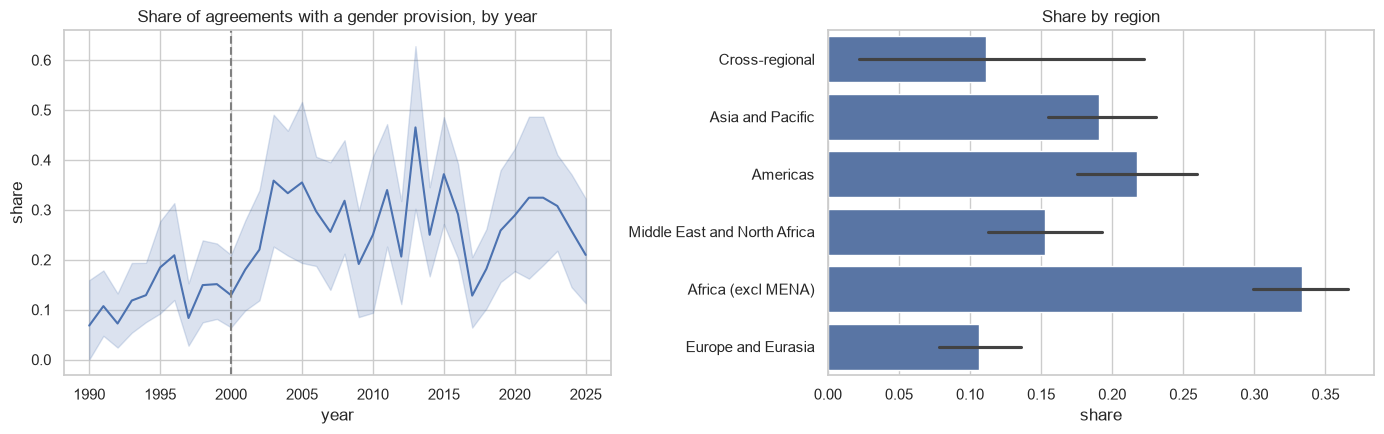

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))  # two charts side by side
sns.lineplot(data=data, x="year", y="gender", ax=axes[0])  # mean of 0/1 per year = share, with 95% band
axes[0].axvline(2000, ls="--", c="gray")  # UN Resolution 1325 (Oct 2000)
axes[0].set(title="Share of agreements with a gender provision, by year", ylabel="share")  # labels
sns.barplot(data=data, x="gender", y="Reg", ax=axes[1], color="#4C72B0")  # share per region, with error bars
axes[1].set(title="Share by region", xlabel="share", ylabel="")  # labels
plt.tight_layout(); plt.show()  # fit spacing and draw

The dashed line is October 2000, when the UN Security Council passed **Resolution 1325** on Women, Peace and Security. The share of agreements mentioning women climbs clearly after it, so `year` should be a strong predictor.

## 4. Split into training and test sets

`train_test_split` shuffles the rows at random and keeps 25% aside for testing.

- `stratify=y` splits the Yes and No agreements separately, so both sets keep the same 21.9% Yes share.
- `random_state=42` fixes the shuffle, so every run puts the same rows in the same set. The number itself has no meaning.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(  # random 75/25 split...
    X, y, test_size=0.25, stratify=y, random_state=42)  # ...same Yes share in both sets, fixed seed

pd.DataFrame({"agreements": [len(y_train), len(y_test)],  # rows in each set
              "mention women": [y_train.sum(), y_test.sum()],  # Yes count in each set
              "share": [y_train.mean().round(3), y_test.mean().round(3)]},  # Yes share in each set
             index=["training", "test"])  # row labels

,agreements,mention women,share
training,1692,370,0.219
test,565,124,0.219


## 5. Baseline and a first decision tree

In [6]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)  # always predicts "No"
print("Baseline (always 'No') accuracy:", round(dummy.score(X_test, y_test), 3))  # accuracy to beat

tree4 = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42).fit(X_train, y_train)  # first tree, 4 levels, Yes weighted up
print("Depth-4 tree test AUC:", round(roc_auc_score(y_test, tree4.predict_proba(X_test)[:, 1]), 3))  # AUC from predicted Yes probabilities

Baseline (always 'No') accuracy: 0.781
Depth-4 tree test AUC: 0.679


`class_weight="balanced"` makes each Yes agreement count about 3.5 times as much as a No agreement during training. Without it, the tree would mostly learn to say "No".

## 6. Tune the tree with cross-validation

`GridSearchCV` tries every combination of tree depth and minimum leaf size. Each combination is scored by 5-fold stratified cross-validation **inside the training set**, so the test set stays untouched until the end.

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)  # 5 folds, each with the same Yes share
grid = GridSearchCV(  # try every parameter combination...
    DecisionTreeClassifier(class_weight="balanced", random_state=42),  # ...on a balanced tree
    {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20, 40]},  # 7 x 5 = 35 combinations
    cv=cv, scoring="roc_auc")  # score each by cross-validated AUC
grid.fit(X_train, y_train)  # runs 35 x 5 = 175 fits on training data only
print("Best parameters:", grid.best_params_, "| CV AUC:", round(grid.best_score_, 3))  # winning combination

res = pd.DataFrame(grid.cv_results_)[["param_max_depth", "param_min_samples_leaf", "mean_test_score"]]  # all results as a table
res.sort_values("mean_test_score", ascending=False).head(5)  # top 5 combinations

Best parameters: {'max_depth': None, 'min_samples_leaf': 20} | CV AUC: 0.727


,param_max_depth,param_min_samples_leaf,mean_test_score
33,None,20,0.726864
27,8,10,0.722519
28,8,20,0.720745
26,8,5,0.717822
32,None,10,0.717546


In [8]:
best_tree = grid.best_estimator_  # best tree, refit on all training data
t = best_tree.tree_  # low-level tree structure (nodes, thresholds, children)
print("nodes:", t.node_count, "| leaves:", best_tree.get_n_leaves(), "| depth:", best_tree.get_depth())  # tree size

nodes: 121 | leaves: 61 | depth: 13


## 7. Read the tree

The default `plot_tree` output is hard to read, so the function below draws the top three levels with plain-language questions.

- The bold text above a box is the question that box asks.
- Each box shows how many **training** agreements reach it and how many mention women.
- Blue boxes predict YES, orange boxes predict NO.

**Direction of the arrows.** sklearn sends rows with `value <= threshold` to the left. For `year`, left means "Yes, signed on or before that year". For a 0/1 column such as `Stage_Cea`, left means the value is 0, which is "No".

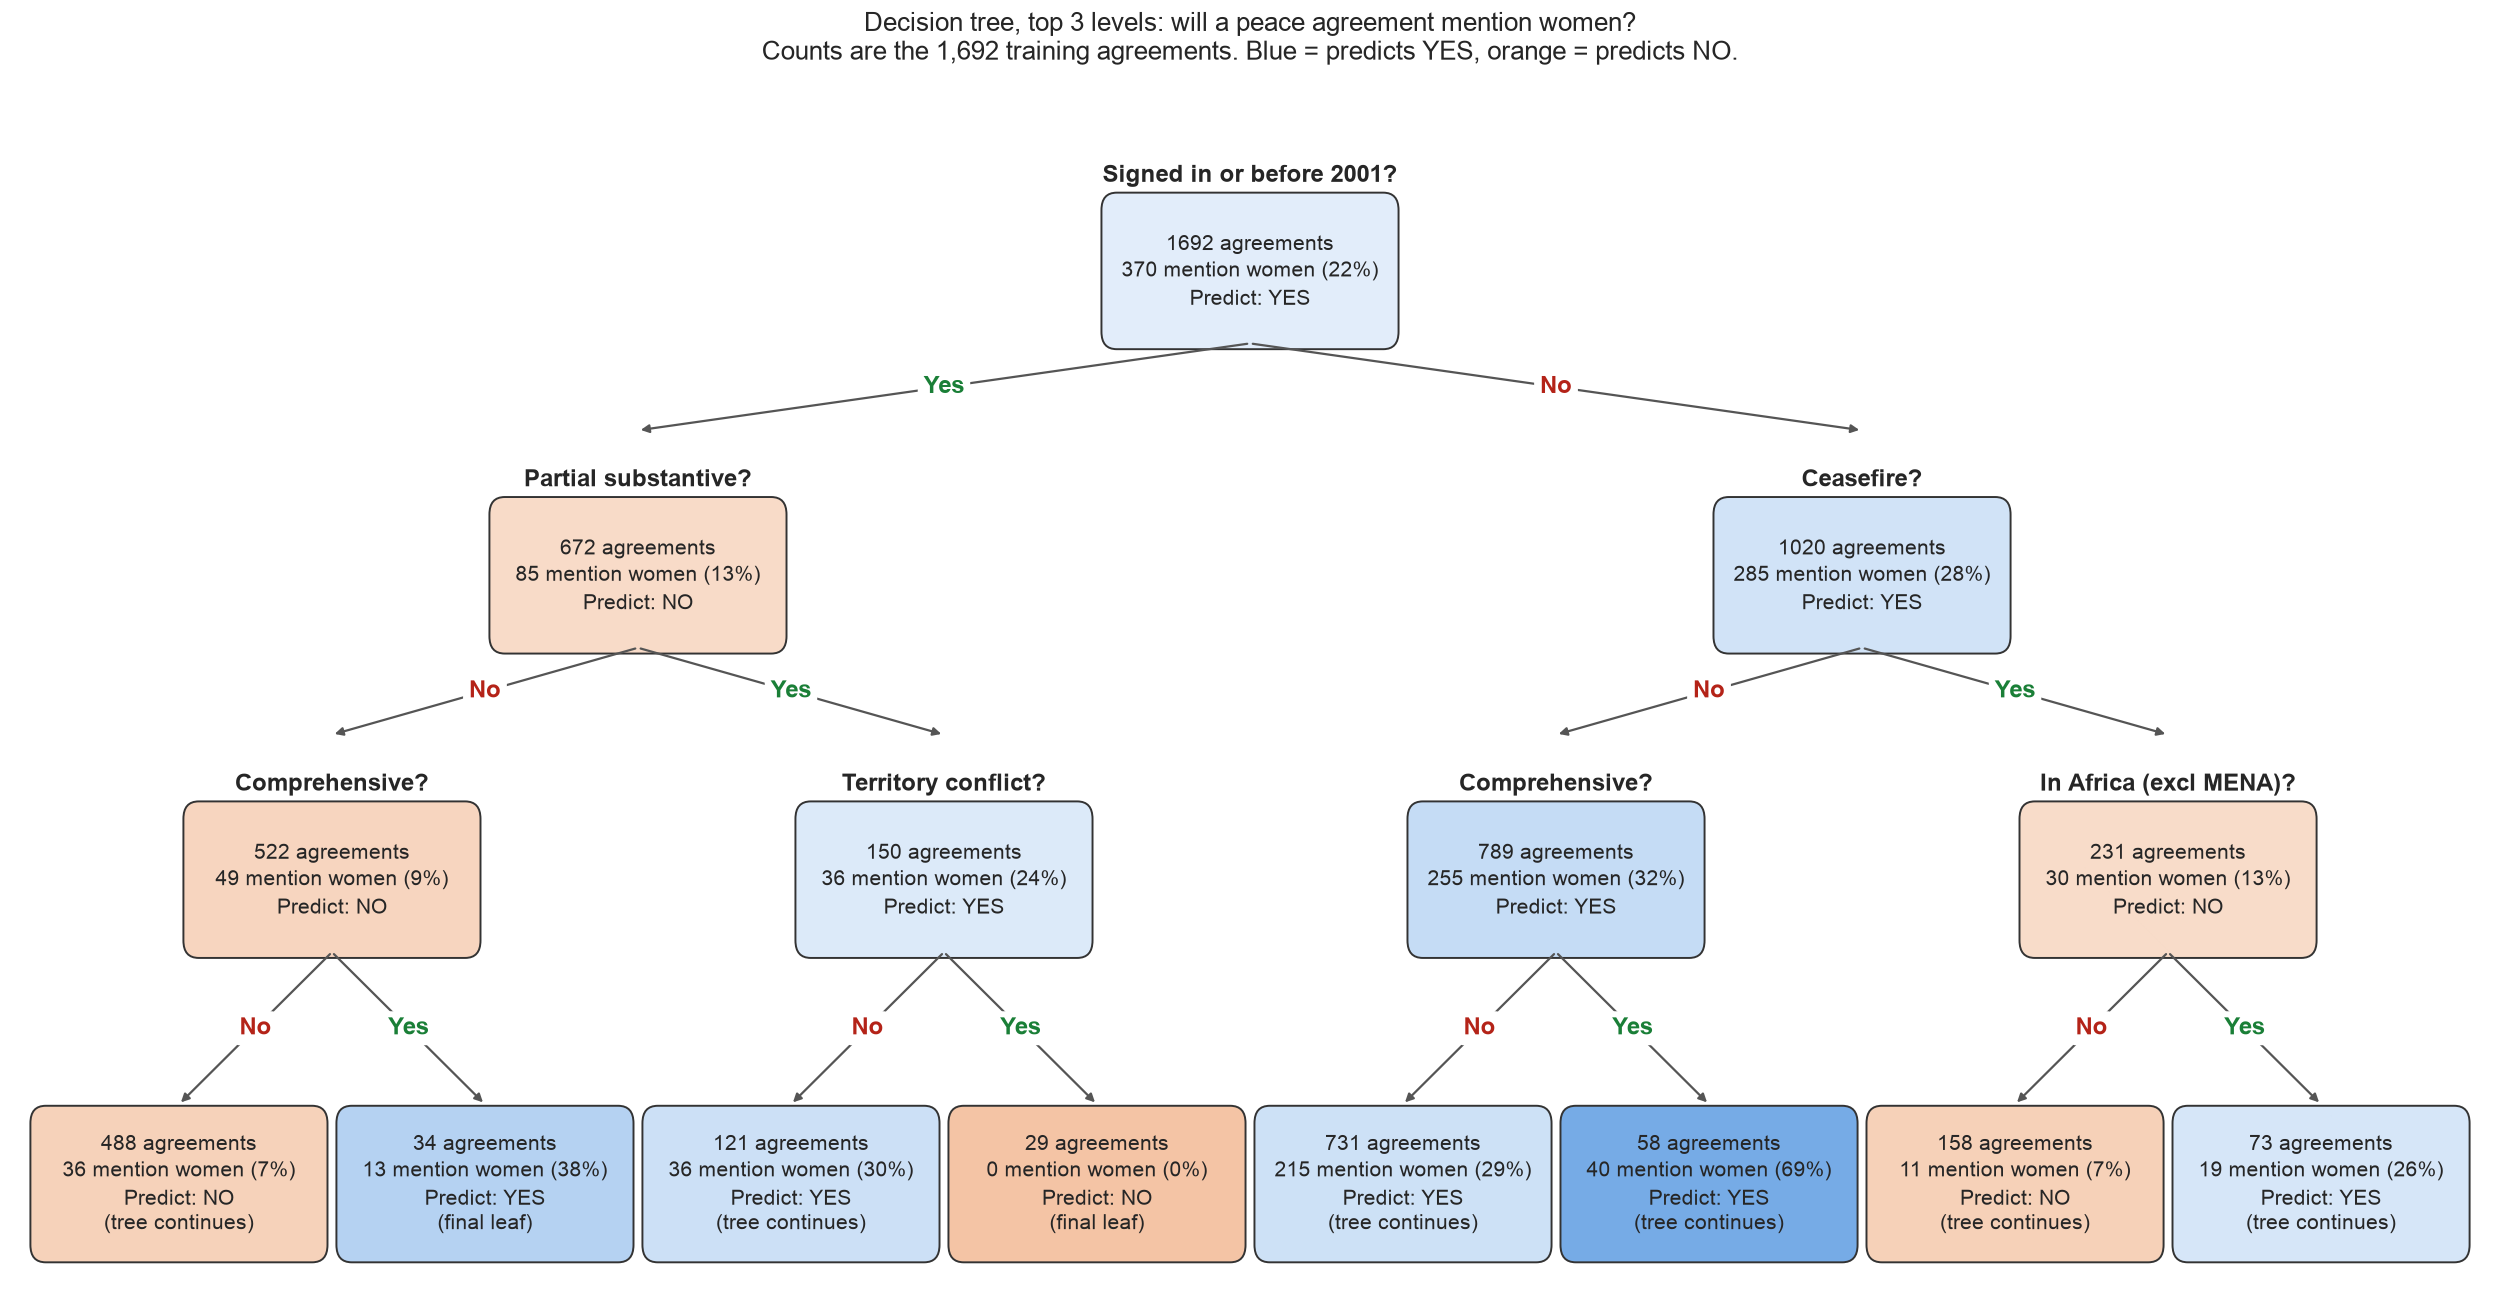

In [9]:
NICE = {  # plain-language question for each column
    "year": "Signed in or before {t}?",  # {t} is filled with the year threshold
    "Stage_SubPar": "Partial substantive?", "Stage_SubComp": "Comprehensive?", "Stage_Cea": "Ceasefire?",  # stage questions
    "Stage_Pre": "Pre-negotiation?", "Stage_Imp": "Implementation?", "Stage_Ren": "Renewal?",  # stage questions
    "Contp_Territory": "Territory conflict?", "Contp_Inter-group": "Inter-group conflict?",  # conflict type questions
    "Contp_Government": "Government conflict?", "Agtp_Intra": "National-level, within\none country?",  # conflict type / level
    "Reg_Africa (excl MENA)": "In Africa (excl MENA)?", "ImOth": "Other international\nsignatory?",  # region / signer
    "ImUN": "UN signatory?", "third_party": "Any third party listed?",  # signer flags
}

def draw_tree(model, X_ref, X_tr, y_tr, maxd=3):  # draw the top maxd levels of a fitted tree
    t = model.tree_  # tree internals
    paths = model.decision_path(X_tr).toarray().astype(bool)  # which nodes each training row passes through
    n_raw = paths.sum(0)  # unweighted row count per node
    yes_raw = (paths & y_tr.values[:, None].astype(bool)).sum(0)  # Yes count per node
    base = y_tr.mean()  # overall Yes share (for color strength)
    pos, edges, slot = {}, [], [0]  # node positions, arrows, next free column

    def layout(i, d):  # place node i at depth d (children first)
        kids = [] if (t.children_left[i] == -1 or d == maxd) else [t.children_left[i], t.children_right[i]]  # stop at leaves or maxd
        if not kids:  # bottom box: take the next column
            pos[i] = (slot[0] * 2.4, d); slot[0] += 1; return  # 2.4 units between columns
        is_year = X_ref.columns[t.feature[i]] == "year"  # year splits read the other way round
        for k, is_left in zip(kids, (True, False)):  # left child, then right child
            layout(k, d + 1)  # place the child first
            edges.append((i, k, "Yes" if is_left == is_year else "No"))  # left = value <= threshold: Yes for year, No for 0/1
        pos[i] = (np.mean([pos[k][0] for k in kids]), d)  # parent centered over its children
    layout(0, 0)  # start at the root

    W, H = 2.25, 1.0  # box width and height
    fig, ax = plt.subplots(figsize=(32, 16))  # big canvas so text stays readable
    blue, orange = np.array([0.23, 0.53, 0.86]), np.array([0.90, 0.49, 0.22])  # YES / NO colors
    for p, k, ans in edges:  # draw each arrow
        (x0, d0), (x1, d1) = pos[p], pos[k]  # parent and child positions
        ya = -d0 * 2.1 - H / 2  # arrow start: bottom of parent box
        yb = -d1 * 2.1 + H / 2 + (0.5 if (t.children_left[k] != -1 and d1 < maxd) else 0.05)  # arrow end: above child's question
        ax.annotate("", xy=(x1, yb), xytext=(x0, ya), arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#555"))  # the arrow
        ax.text((x0 + x1) / 2, (ya + yb) / 2, ans, ha="center", va="center", fontsize=17, fontweight="bold",  # Yes/No label mid-arrow
                color="#1a7f37" if ans == "Yes" else "#b42318", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none"))  # green Yes, red No
    for i, (x, d) in pos.items():  # draw each box
        share = yes_raw[i] / n_raw[i]  # Yes share in this box
        pred_yes = t.value[i][0][1] > t.value[i][0][0]  # weighted majority decides the prediction
        strength = min(abs(share - base) / 0.4, 1) * 0.55 + 0.15  # further from 22% = darker color
        col = (blue if pred_yes else orange) * strength + (1 - strength)  # blend color with white
        yc = -d * 2.1  # vertical center of the box
        ax.add_patch(FancyBboxPatch((x - W / 2, yc - H / 2), W, H, boxstyle="round,pad=0.04,rounding_size=0.12",  # rounded box...
                                    fc=col, ec="#333", lw=1.4))  # ...fill and border
        lines = f"{n_raw[i]} agreements\n{yes_raw[i]} mention women ({share:.0%})\nPredict: {'YES' if pred_yes else 'NO'}"  # box text
        if t.children_left[i] != -1 and d < maxd:  # split shown in the picture
            f = X_ref.columns[t.feature[i]]  # column this node splits on
            ax.text(x, yc + H / 2 + 0.08, NICE.get(f, f + "?").format(t=int(np.floor(t.threshold[i]))),  # question above the box...
                    ha="center", va="bottom", fontsize=17, fontweight="bold")  # ...in bold
        elif t.children_left[i] != -1:  # split exists but is below maxd
            lines += "\n(tree continues)"  # mark it
        else:  # true leaf
            lines += "\n(final leaf)"  # mark it
        ax.text(x, yc, lines, ha="center", va="center", fontsize=15, linespacing=1.35)  # text inside the box
    ax.set_xlim(-W / 2 - 0.2, (slot[0] - 1) * 2.4 + W / 2 + 0.2)  # fit all columns
    ax.set_ylim(-maxd * 2.1 - H / 2 - 0.3, H / 2 + 0.9)  # fit all levels
    ax.axis("off")  # no axes or ticks
    ax.set_title(f"Decision tree, top {maxd} levels: will a peace agreement mention women?\n"  # title line 1
                 f"Counts are the {len(y_tr):,} training agreements. Blue = predicts YES, orange = predicts NO.", fontsize=19)  # title line 2
    plt.show()  # draw

draw_tree(best_tree, X, X_train, y_train)  # draw the tuned tree

**How to read it.** The first question is the year: agreements signed after 2001 mention women far more often. After that, **stage** dominates: ceasefires rarely mention women, while comprehensive agreements usually do. Region and conflict type only appear lower down, inside particular branches.

The full tree is much deeper. `export_text` prints every rule; each indented line is one more question on the path.

In [10]:
print(export_text(best_tree, feature_names=list(X.columns), max_depth=5))  # every rule as indented text, 5 levels

|--- year <= 2001.50
|   |--- Stage_SubPar <= 0.50
|   |   |--- Stage_SubComp <= 0.50
|   |   |   |--- Agtp_Intra <= 0.50
|   |   |   |   |--- Stage_Pre <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Stage_Pre >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- Agtp_Intra >  0.50
|   |   |   |   |--- Stage_Cea <= 0.50
|   |   |   |   |   |--- Reg_Americas <= 0.50
|   |   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |   |--- Reg_Americas >  0.50
|   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- Stage_Cea >  0.50
|   |   |   |   |   |--- Contp_Government <= 0.50
|   |   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |   |--- Contp_Government >  0.50
|   |   |   |   |   |   |--- class: 0
|   |   |--- Stage_SubComp >  0.50
|   |   |   |--- class: 1
|   |--- Stage_SubPar >  0.50
|   |   |--- Contp_Territory <= 0.50
|   |   |   |--- year <= 1994.50
|   |   |   |   |--- year <= 1992.50
|   |   |   |   |  

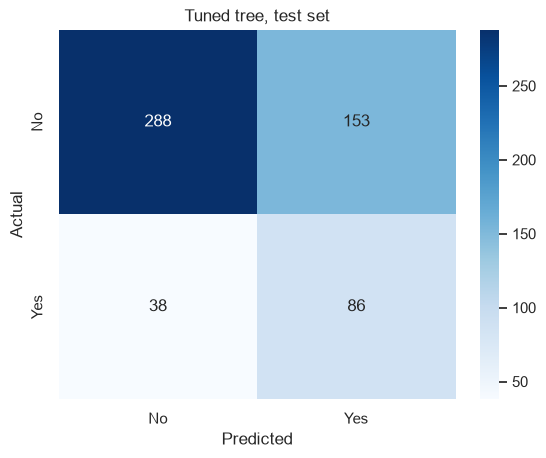

In [11]:
pred = best_tree.predict(X_test)  # Yes/No predictions on the test set
cm = confusion_matrix(y_test, pred)  # rows = actual, columns = predicted
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])  # confusion matrix as a heatmap
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Tuned tree, test set"); plt.show()  # labels and draw

The bottom-right cell counts agreements that do mention women and were caught (true positives). The bottom-left cell counts the ones the tree missed. Because of the balanced weights, the tree catches most Yes agreements, at the cost of some false alarms in the top-right cell.

## 8. Compare with a random forest and gradient boosting

- A **random forest** averages 300 trees, each grown on a bootstrap sample with random subsets of features. That makes it much more stable than one tree.
- **Gradient boosting** builds small trees one after another, each correcting the last. `GradientBoostingClassifier` has no `class_weight` option, so we pass balanced `sample_weight` instead. The unweighted version is shown for comparison.

In [12]:
models = {  # models to compare
    "Tree": best_tree,  # tuned tree (already fitted)
    "Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),  # 300 balanced trees
    "Boosting (weighted)": GradientBoostingClassifier(random_state=42),  # boosting, weighted when fitted
    "Boosting (unweighted)": GradientBoostingClassifier(random_state=42),  # boosting, no weights
}
w = compute_sample_weight("balanced", y_train)  # Yes rows weighted ~3.5x for boosting
rows = []  # collect one row per result
for name, m in models.items():  # fit and score each model
    if name == "Boosting (weighted)":  # boosting has no class_weight option...
        m.fit(X_train, y_train, sample_weight=w)  # ...so pass row weights instead
    elif name != "Tree":  # the tree is already fitted
        m.fit(X_train, y_train)  # fit forest / unweighted boosting
    p = m.predict_proba(X_test)[:, 1]; yh = m.predict(X_test)  # Yes probability and Yes/No prediction
    rows.append([name, accuracy_score(y_test, yh), precision_score(y_test, yh),  # accuracy, precision...
                 recall_score(y_test, yh), f1_score(y_test, yh), roc_auc_score(y_test, p)])  # ...recall, F1, AUC
pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "F1", "ROC AUC"]).round(3)  # comparison table

,model,accuracy,precision,recall,F1,ROC AUC
0,Tree,0.662,0.360,0.694,0.474,0.727
1,Forest,0.747,0.435,0.516,0.472,0.761
2,Boosting (weighted),0.699,0.384,0.613,0.472,0.753
3,Boosting (unweighted),0.805,0.652,0.242,0.353,0.742


The unweighted boosting model has the best accuracy but the worst recall: it misses most agreements that mention women. For this question, recall and AUC matter more than accuracy.

## 9. Feature importance

The forest's built-in importance scores each **dummy column** separately, so region's importance is spread across six columns and looks smaller than it is.

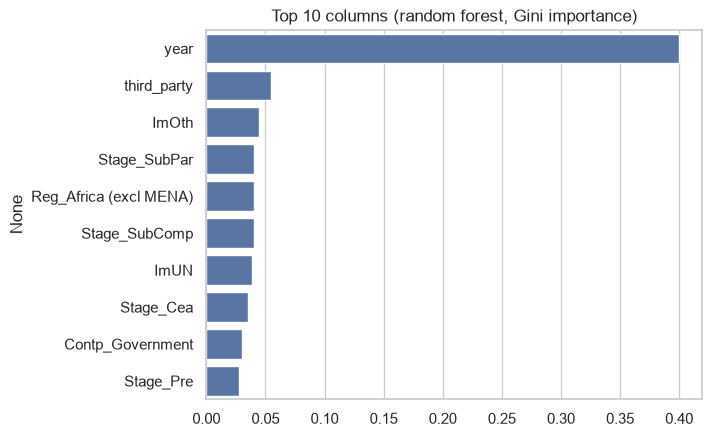

In [13]:
forest = models["Forest"]  # fitted random forest
imp = pd.Series(forest.feature_importances_, index=X.columns).nlargest(10)  # 10 most important columns
sns.barplot(x=imp.values, y=imp.index, color="#4C72B0")  # horizontal bars
plt.title("Top 10 columns (random forest, Gini importance)"); plt.show()  # title and draw

To compare the eight original features fairly, we group the dummy columns back together in two ways:

- **Grouped Gini importance:** add up the importance of all dummy columns of a feature.
- **Grouped permutation importance:** shuffle all of a feature's columns together in the test set and measure how much test AUC drops. If the model needs the feature, the AUC falls.

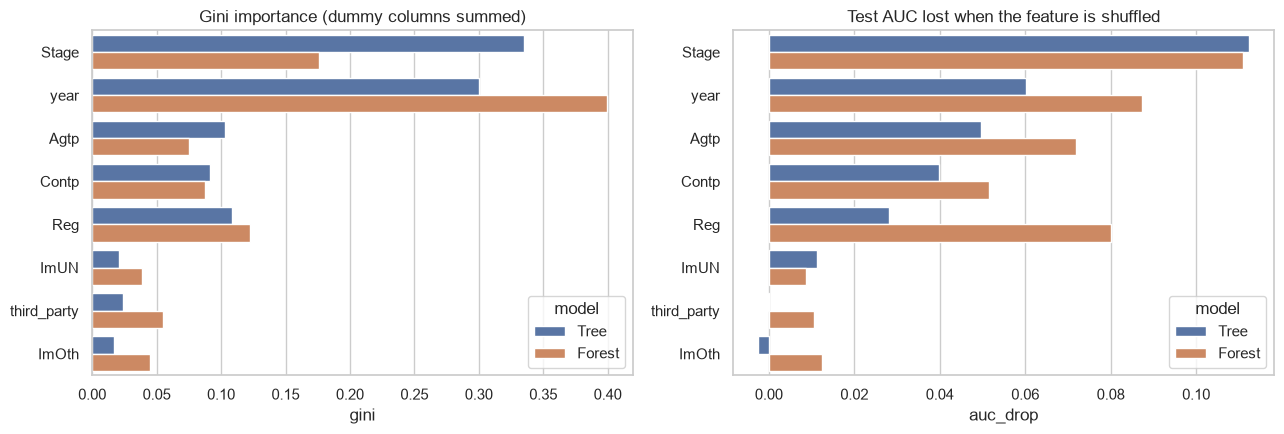

,model,feature,kind,gini,auc_drop
0,Tree,year,num,0.300,0.060
1,Tree,ImUN,num,0.021,0.011
2,Tree,ImOth,num,0.017,-0.003
3,Tree,third_party,num,0.024,-0.000
4,Tree,Reg,cat,0.109,0.028
5,Tree,Contp,cat,0.092,0.040
6,Tree,Agtp,cat,0.103,0.050
7,Tree,Stage,cat,0.335,0.112
8,Forest,year,num,0.400,0.087
9,Forest,ImUN,num,0.039,0.009


In [14]:
def group(col):  # map a dummy column back to its original feature
    for c in cat:  # check each categorical feature
        if col.startswith(c + "_"):  # e.g. "Stage_Cea" starts with "Stage_"
            return c  # belongs to that feature
    return col  # numeric columns keep their own name

rng = np.random.default_rng(42)  # fixed random generator for shuffling
rows = []  # collect one row per result
for name, m in [("Tree", best_tree), ("Forest", forest)]:  # both models
    base_auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])  # AUC before shuffling
    gini = pd.Series(m.feature_importances_, index=X.columns).groupby(group).sum()  # Gini importance summed per feature
    for f in num + cat:  # each of the 8 features
        cols = [c for c in X.columns if group(c) == f]  # all its columns
        drops = []  # AUC drop for each shuffle
        for _ in range(20):  # repeat 20 times to average out luck
            Xp = X_test.copy()  # copy of the test set
            Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]  # shuffle the feature's columns together
            drops.append(base_auc - roc_auc_score(y_test, m.predict_proba(Xp)[:, 1]))  # how much AUC fell
        rows.append([name, f, "num" if f in num else "cat", gini[f], np.mean(drops)])  # one row per model x feature
gi = pd.DataFrame(rows, columns=["model", "feature", "kind", "gini", "auc_drop"])  # results table

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))  # two charts side by side
order = gi[gi.model == "Tree"].sort_values("auc_drop", ascending=False).feature  # sort features by the tree's AUC drop
sns.barplot(data=gi, x="gini", y="feature", hue="model", order=order, ax=axes[0])  # grouped Gini importance
axes[0].set(title="Gini importance (dummy columns summed)", ylabel="")  # labels
sns.barplot(data=gi, x="auc_drop", y="feature", hue="model", order=order, ax=axes[1])  # permutation importance
axes[1].set(title="Test AUC lost when the feature is shuffled", ylabel="")  # labels
plt.tight_layout(); plt.show()  # fit spacing and draw
gi.round(3)  # show the numbers

**Stage** is the strongest feature, followed by **year**. Conflict type and agreement level carry overlapping information (territory conflicts are mostly interstate agreements, inter-group conflicts mostly local ones), so each looks modest on its own, but together they matter about as much as stage. Of the signer flags, only `ImUN` adds much.

## 10. Deep dives

The models say *which* features matter. The next sections ask *how*: which values push the chance of a gender provision up or down.

We use two tools:
- **Raw share**: for each group, the number of agreements that mention women divided by the number of agreements in that group, over all 2,257 agreements. The 95% interval uses the Wilson method, which behaves well for small groups.
- **Odds ratio with controls**: a logistic regression that includes all eight features at once. An odds ratio above 1 means the group mentions women more often than the reference group *after holding the other features constant*; below 1 means less often.

A few tiny categories are dropped from the regression because they have no Yes cases at all, which makes the model unable to estimate them ("perfect separation"): Stage `Oth`, Contp `Other` and Agtp `Inter`.

In [15]:
def wilson(k, n, z=1.96):  # 95% Wilson interval for k successes out of n
    p = k / n; d = 1 + z**2 / n  # raw share and denominator
    c = (p + z**2 / (2 * n)) / d  # interval center
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d  # half-width
    return c - h, c + h  # (low, high)

def shares(col, labels=None):  # Yes share per group of a column
    s = df.groupby(col).gender.agg(yes="sum", n="size").reset_index()  # Yes count and total per group
    if labels:  # optional readable names
        s[col] = s[col].map(labels)  # e.g. "SubComp" -> "Comprehensive"
    s["share"] = s.yes / s.n  # share = Yes / total
    s[["lo", "hi"]] = [wilson(k, n) for k, n in zip(s.yes, s.n)]  # 95% interval per group
    return s.sort_values("share", ascending=False)  # highest share first

reg_df = df[(df.Stage != "Oth") & (df.Contp != "Other") & (df.Agtp != "Inter")]  # drop tiny groups with no Yes (perfect separation)
logit = smf.logit(  # logistic regression with all 8 features...
    "gender ~ C(Stage, Treatment('Pre')) + C(Reg, Treatment('Africa (excl MENA)'))"  # ...stage vs pre-negotiation, region vs Africa
    " + C(Contp, Treatment('Government/territory')) + C(Agtp) + year + ImUN + ImOth + third_party",  # ...conflict type vs gov/territory, plus the rest
    reg_df).fit(disp=0, maxiter=300)  # fit quietly
print("Regression rows:", len(reg_df))  # rows used

def odds(prefix, labels=None):  # odds ratios for the terms starting with prefix
    ci = logit.conf_int()  # 95% intervals on the log-odds scale
    rows = []  # collect one row per result
    for k, v in logit.params.items():  # every coefficient
        if k.startswith(prefix):  # only this feature's terms
            name = k.split("[T.")[1].rstrip("]") if "[T." in k else k  # "C(Reg...)[T.Americas]" -> "Americas"
            rows.append([labels.get(name, name) if labels else name, np.exp(v),  # exp(coefficient) = odds ratio...
                         np.exp(ci.loc[k, 0]), np.exp(ci.loc[k, 1]), logit.pvalues[k]])  # ...its interval and p-value
    return pd.DataFrame(rows, columns=["group", "OR", "lo", "hi", "p"])  # table of odds ratios

def share_and_odds_plot(s, col, o, ref, title):  # raw share chart next to odds-ratio chart
    order = s[col].tolist()  # same group order in both charts
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.55 * len(s) + 1.8), gridspec_kw={"width_ratios": [1.2, 1]})  # height grows with groups
    ax = axes[0]  # left chart: raw share
    sns.barplot(data=s, x="share", y=col, order=order, color="#4C72B0", ax=ax)  # share bars
    ax.errorbar(s.share, range(len(s)), xerr=[s.share - s.lo, s.hi - s.share], fmt="none", c="k", capsize=3, lw=1)  # Wilson interval
    ax.axvline(df.gender.mean(), ls="--", c="gray")  # overall 21.9%
    for i, r in enumerate(s.itertuples()):  # label each bar
        ax.text(r.hi + 0.01, i, f"{r.share:.1%}  ({r.yes} of {r.n})", va="center", fontsize=9)  # e.g. "58.9% (73 of 124)"
    ax.set(xlim=(0, 1), ylabel="", xlabel="Share with a gender provision (95% CI)",  # axis labels...
           title=f"Raw share by {title} (dashed = overall {df.gender.mean():.1%})")  # ...and title
    ax = axes[1]  # right chart: odds ratios
    o = pd.concat([pd.DataFrame([[ref, 1.0, 1.0, 1.0, np.nan]], columns=o.columns), o])  # add the reference group at 1.0
    o = o.set_index("group").reindex([g for g in order if g in o.group.values]).reset_index()  # match left chart order
    ax.errorbar(o.OR, range(len(o)), xerr=[o.OR - o.lo, o.hi - o.OR], fmt="o", c="#C44E52", capsize=3)  # dot + interval
    ax.axvline(1, ls="--", c="gray"); ax.set_xscale("log")  # 1 = no difference; log scale
    ticks = [0.1, 0.25, 0.5, 1, 2, 5, 10]  # readable tick values
    ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())  # no overlapping minor ticks
    ax.set_xticks(ticks); ax.set_xticklabels([str(x) for x in ticks])  # plain numbers, not 10^x
    ax.set_yticks(range(len(o))); ax.set_yticklabels(o.group); ax.invert_yaxis()  # group names, top to bottom
    ax.set(xlabel=f"Odds ratio vs {ref} (log scale)", title="Holding the other features constant")  # labels
    plt.tight_layout(); plt.show()  # fit spacing and draw

Regression rows: 2151


### 10a. Do the signer flags matter? (`ImUN`, `ImOth`, `third_party`)

For each flag we compare the share with and without it, then check whether the difference survives once the other features are held constant.

In [16]:
flags = ["ImUN", "ImOth", "third_party"]  # the three signer flags
rows = []  # collect one row per result
ors = odds("ImUN").pipe(lambda o: pd.concat([o, odds("ImOth"), odds("third_party")]))  # their odds ratios in one table
for f in flags:  # one row per flag
    g = df.groupby(f).gender.agg(["sum", "size", "mean"])  # Yes count, total, share for flag 0 and 1
    p = chi2_contingency(pd.crosstab(df[f], df.gender))[1]  # p-value with no controls
    r = ors[ors.group == f].iloc[0]  # odds ratio with controls
    rows.append([f, f"{g.loc[0,'mean']:.1%} ({int(g.loc[0,'sum'])}/{int(g.loc[0,'size'])})",  # share when flag = 0
                 f"{g.loc[1,'mean']:.1%} ({int(g.loc[1,'sum'])}/{int(g.loc[1,'size'])})", p,  # share when flag = 1
                 round(r.OR, 2), f"{r.lo:.2f} to {r.hi:.2f}", r.p])  # controlled result
pd.DataFrame(rows, columns=["flag", "share when 0", "share when 1", "chi-square p",  # results table...
                            "OR with controls", "95% CI", "p with controls"])  # ...column names

,flag,share when 0,share when 1,chi-square p,OR with controls,95% CI,p with controls
0,ImUN,20.3% (361/1779),27.8% (133/478),0.000514,1.69,1.27 to 2.25,0.000362
1,ImOth,21.1% (349/1654),24.0% (145/603),0.149797,0.80,0.60 to 1.06,0.119827
2,third_party,17.9% (183/1021),25.2% (311/1236),0.000043,1.10,0.85 to 1.42,0.460053


- **`ImUN`**: agreements with a UN signatory mention women more often, and the effect survives the controls.
- **`third_party`**: on its own it looks related to the outcome (25% vs 18%), but that is mostly because third parties are more common in certain stages and years. Once those are held constant, the effect disappears.
- **`ImOth`**: no clear relationship even on its own.

### 10b. Stage

The PA-X codebook defines seven stages:

| Code | Stage | What it is |
|---|---|---|
| `Pre` | Pre-negotiation | Gets the parties to the table: talks about how to talk |
| `SubPar` | Partial substantive | Agrees on some core issues, expecting more agreements later |
| `SubComp` | Comprehensive | A full attempt to resolve the whole conflict |
| `Imp` | Implementation | Carries out or renegotiates an earlier agreement |
| `Ren` | Renewal | Short, often one page, only renews earlier commitments |
| `Cea` | Ceasefire | Only a ceasefire, demobilisation or its monitoring |
| `Oth` | Other | Anything that fits none of the above |

**How the share column is calculated:** for each stage, the number of agreements that mention women divided by the number of agreements at that stage. For example, comprehensive = 73 ÷ 124 = 58.9%.

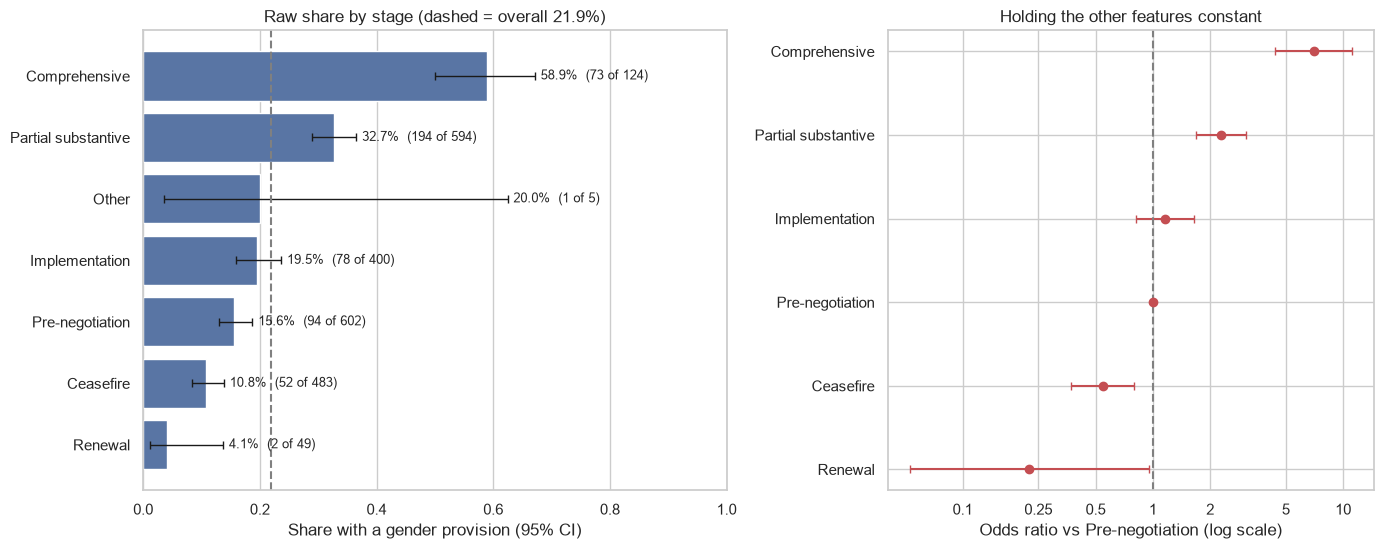

,Stage,yes,n,share,lo_x,hi_x,OR,lo_y,hi_y,p
0,Comprehensive,73,124,0.589,0.501,0.671,6.994,4.401,11.115,0.000
1,Partial substantive,194,594,0.327,0.290,0.365,2.288,1.688,3.102,0.000
2,Other,1,5,0.200,0.036,0.624,NaN,NaN,NaN,NaN
3,Implementation,78,400,0.195,0.159,0.237,1.160,0.815,1.652,0.409
4,Pre-negotiation,94,602,0.156,0.129,0.187,NaN,NaN,NaN,NaN
5,Ceasefire,52,483,0.108,0.083,0.138,0.544,0.371,0.798,0.002
6,Renewal,2,49,0.041,0.011,0.137,0.224,0.053,0.949,0.042


In [17]:
STAGES = {"Pre": "Pre-negotiation", "SubPar": "Partial substantive", "SubComp": "Comprehensive",  # stage codes -> names
          "Imp": "Implementation", "Ren": "Renewal", "Cea": "Ceasefire", "Oth": "Other"}  # stage codes -> names
st = shares("Stage", STAGES)  # raw share per stage
st_or = odds("C(Stage", STAGES)  # odds ratio per stage vs pre-negotiation
share_and_odds_plot(st, "Stage", st_or, "Pre-negotiation", "stage")  # both charts
st.merge(st_or.rename(columns={"group": "Stage"}), on="Stage", how="left").round(3)  # one table with both (_x = share CI, _y = OR CI)

Comprehensive agreements are about **7 times** as likely (in odds) to mention women as pre-negotiation agreements, even after controlling for year, region and the rest. They are long documents covering governance, rights, elections and justice, so there is room for gender provisions. Ceasefires and renewals are short and narrow, and rarely mention women.

### 10c. Region

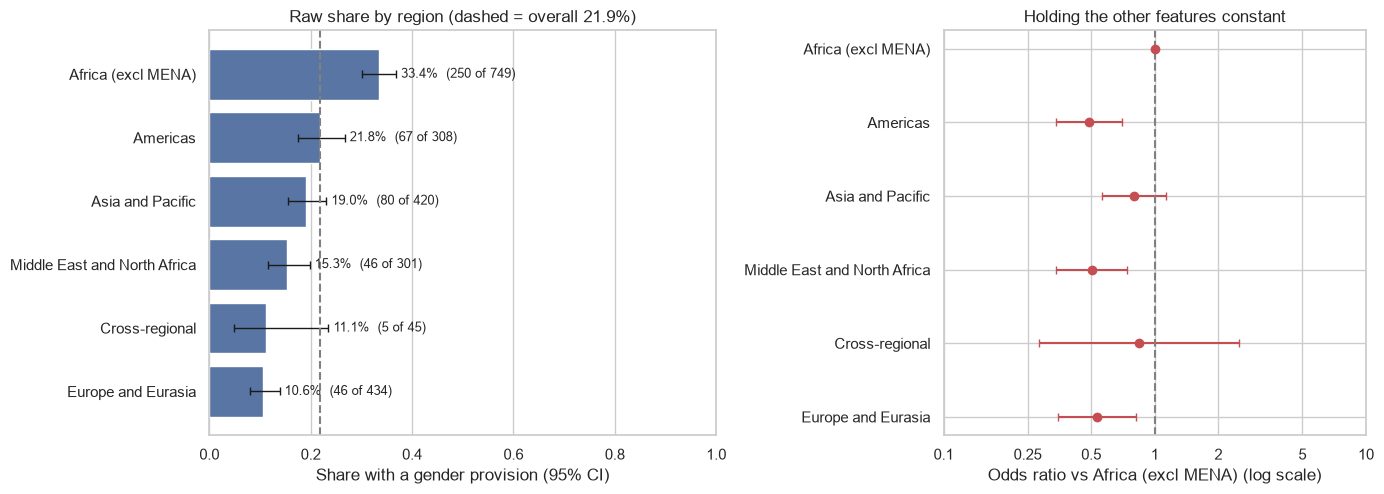

,group,OR,lo,hi,p
0,Americas,0.487,0.340,0.698,0.000
1,Asia and Pacific,0.800,0.565,1.133,0.209
2,Cross-regional,0.844,0.283,2.516,0.761
3,Europe and Eurasia,0.532,0.348,0.812,0.003
4,Middle East and North Africa,0.503,0.341,0.742,0.001


In [18]:
rg = shares("Reg")  # raw share per region
rg_or = odds("C(Reg")  # odds ratio per region vs Africa
share_and_odds_plot(rg, "Reg", rg_or, "Africa (excl MENA)", "region")  # both charts
rg_or.round(3)  # odds ratio table

Africa has the highest share (33%), and it stays ahead of the Americas, the Middle East and North Africa, and Europe and Eurasia even after controls: their odds are about half of Africa's. Asia and Pacific is not clearly different from Africa once the other features are held constant. Part of the raw gap between regions comes from *when* and *at what stage* each region signed its agreements, which is why the odds ratios are closer to 1 than the raw shares suggest.

### 10d. Conflict type

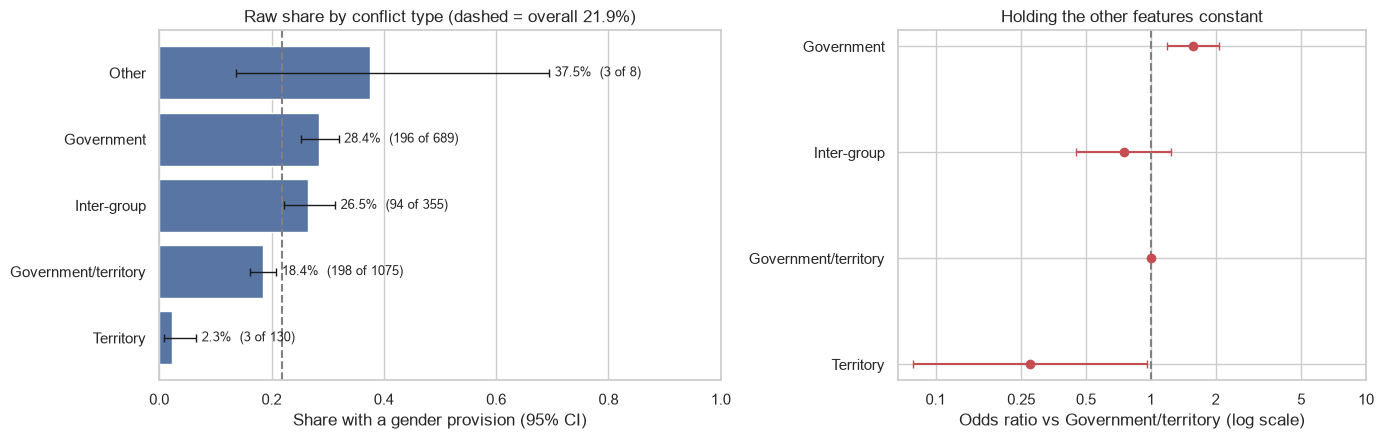

,group,OR,lo,hi,p
0,Government,1.574,1.196,2.072,0.001
1,Inter-group,0.747,0.448,1.246,0.264
2,Territory,0.276,0.079,0.963,0.044


Agtp,Inter,InterIntra,Intra,IntraLocal
Contp,,,,
Government,0,79,575,35
Government/territory,7,161,856,51
Inter-group,3,0,50,302
Other,0,1,0,7
Territory,84,37,8,1


In [19]:
ct = shares("Contp")  # raw share per conflict type
ct_or = odds("C(Contp")  # odds ratio vs government/territory
share_and_odds_plot(ct, "Contp", ct_or, "Government/territory", "conflict type")  # both charts
display(ct_or.round(3))  # odds ratio table
pd.crosstab(df.Contp, df.Agtp)  # conflict type x agreement level counts

Conflicts over **government** mention women most often (28%), and stay higher than mixed government/territory conflicts after controls. **Territory** conflicts almost never do (3 of 130, 2%): they are mostly interstate border deals. The crosstab shows why conflict type and agreement level overlap: most territory conflicts are settled with interstate agreements and most inter-group conflicts with local ones, so the two features carry much of the same information.

## 11. How the tree chooses each question

Nobody picks the questions by hand. At every box the tree:

1. Tries **every column** and, for `year`, every cut-off.
2. For each candidate, splits the box's agreements into Yes and No and measures how mixed each side is with **Gini impurity**: 0 means a side is all one answer. Classes are weighted, as in training.
3. Keeps the question that lowers the impurity the most, skipping splits that would leave a side with fewer than `min_samples_leaf` agreements.

The function below repeats that search for any box and lists the runner-ups. Here it is applied to the two third-level boxes where **conflict type** and **region** were chosen.

In [20]:
w1 = len(y_train) / (2 * y_train.sum())  # balanced weight for a Yes row
w0 = len(y_train) / (2 * (len(y_train) - y_train.sum()))  # balanced weight for a No row
min_leaf = best_tree.get_params()["min_samples_leaf"]  # same minimum leaf size as the tree

def gini(yy):  # weighted Gini impurity of a group
    a, b = (yy == 1).sum() * w1, (yy == 0).sum() * w0  # weighted Yes and No
    tot = a + b  # total weight
    return (1 - (a / tot) ** 2 - (b / tot) ** 2, tot) if tot else (0, 0)  # (impurity, weight); 0 = pure

def candidate_splits(mask, top=5):  # best questions for the box selected by mask
    xs, ys = X_train[mask], y_train[mask]  # rows in this box
    g0, t0 = gini(ys)  # impurity before splitting
    best = {}  # best (gain, threshold) per column
    for c in X.columns:  # try every column
        for v in np.unique(xs[c])[:-1]:  # every possible cut-off
            left = xs[c] <= v  # rows sent left
            if left.sum() < min_leaf or (~left).sum() < min_leaf:  # a side would be too small
                continue  # skip it
            gl, tl = gini(ys[left]); gr, tr = gini(ys[~left])  # impurity of each side
            gain = g0 - (gl * tl + gr * tr) / t0  # drop in weighted impurity
            if c not in best or gain > best[c][0]:  # keep the best cut-off per column
                best[c] = (gain, v)  # store it
    out = pd.DataFrame([(c, v, g) for c, (g, v) in best.items()], columns=["column", "threshold", "gain"])  # table of candidates
    return out.sort_values("gain", ascending=False).head(top).reset_index(drop=True)  # top candidates first

print("Box: signed 2001 or earlier AND partial substantive")  # first box
display(candidate_splits((X_train.year <= 2001) & (X_train.Stage_SubPar == 1)).round(4))  # where conflict type wins
print("Box: signed 2002 or later AND ceasefire")  # second box
display(candidate_splits((X_train.year > 2001) & (X_train.Stage_Cea == 1)).round(4))  # where region wins

Box: signed 2001 or earlier AND partial substantive


,column,threshold,gain
0,Contp_Territory,0,0.0763
1,year,1991,0.0646
2,Agtp_Inter,0,0.0533
3,Agtp_Intra,0,0.0204
4,Reg_Europe and Eurasia,0,0.0200


Box: signed 2002 or later AND ceasefire


,column,threshold,gain
0,Reg_Africa (excl MENA),0,0.0572
1,Agtp_Intra,0,0.0503
2,ImOth,0,0.0413
3,Contp_Inter-group,0,0.0389
4,Agtp_IntraLocal,0,0.0372


In the first box, "territory conflict?" wins because none of the territory-conflict agreements there mention women, which makes a very clean No group. In the second, "in Africa?" wins narrowly over "national-level agreement?".

Two lessons:
- The tree is **greedy**: it picks the best question for each box without looking ahead. Margins can be small, so a different random split could swap the winners.
- Each box sees only its own agreements, so a feature that matters in one branch may not matter elsewhere. That is why the forest and the grouped importance (section 9) are a better guide to overall importance than any single box.

## 12. Conclusions and limitations

**Answer to the research question.** Basic facts about an agreement predict a gender provision moderately well: test ROC AUC is about 0.73 for the tuned tree and 0.75 to 0.76 for the forest and weighted boosting, well above the 0.5 of guessing.

- **Stage** matters most. Comprehensive and partial substantive agreements mention women much more often; ceasefires and renewals rarely do.
- **Year** comes next. Agreements after UN Resolution 1325 (2000) are much more likely to include gender provisions.
- **Conflict type and agreement level** overlap, but together they matter about as much as stage. Government conflicts mention women most; territory conflicts almost never.
- **Region**: Africa stays ahead of several other regions after controls.
- **Signers**: only a UN signatory (`ImUN`) has a clear independent effect.

**Limitations**
- The test score comes from one random split. Repeated cross-validation gives similar results, but a different seed shifts the numbers slightly.
- Agreements from the same peace process can land in both training and test sets, which makes the test score a little optimistic. Grouping by peace process (`GroupKFold`) would be stricter.
- `GeWom` only records whether gender is *mentioned*, not how strong or binding the provision is.
- These are associations, not causes. For example, UN involvement may bring gender provisions, or may simply happen more often in processes that would include them anyway.